# 동적프로그래밍 (Dynamic Programming, DP)

## 1. 반복적 정책 평가 (Iterative Policy Evaluation)

####  3×4 그리드 월드의 환경 모델

에이전트는 3×4 격자 위를 움직이며, 사과(목표)에 도달하면 +1, 폭탄에 닿으면 −1의 보상을 받습니다. 가운데 회색 칸은 벽입니다.

<img src="imgs/gridworld_3x4.png" alt="3×4 그리드 월드" width="300">

각 칸은 아래 그림처럼 `(행, 열)` 좌표로 나타내며, 칸의 숫자는 그 칸에 도착했을 때 받는 보상입니다.

<img src="imgs/gridworld_coordi.png" alt="보상 맵의 좌표계" width="300">

좌표는 `(행, 열)`이며 왼쪽 위가 `(0, 0)`입니다.

| 항목 | 규칙 |
| --- | --- |
| 행동 | 0: 위, 1: 아래, 2: 왼쪽, 3: 오른쪽 |
| 시작 | `(2, 0)` |
| 목표 | `(0, 3)`에 들어가면 +1을 받고 종료 |
| 벽 | `(1, 1)`에는 들어갈 수 없음 |
| 폭탄 | `(1, 3)`에 도착하면 −1, **종료하지 않음** |
| 경계·벽으로 이동 | 현재 위치에 머무름 |
| 보상 | **이동 결과의 칸**에 적힌 보상. 일반 칸에서는 0 |

폭탄 칸에서 경계 때문에 제자리에 머무는 경우에도 −1을 받습니다.


In [1]:
import dezerogym.gridworld_render as render_helper

class GridWorld:
    """결정적 전이 모델을 제공하는 3×4 그리드 월드."""

    def __init__(self):
        # 행동 공간과 행동의 의미
        self.action_space = [0, 1, 2, 3]
        self.action_meaning = {
            0: "UP",
            1: "DOWN",
            2: "LEFT",
            3: "RIGHT",
        }

        # 도착한 칸의 보상. None은 이동할 수 없는 벽이다.
        self.reward_map = np.array(
            [[0, 0, 0, 1.0],
             [0, None, 0, -1.0],
             [0, 0, 0, 0]]
        )
        # 목표, 벽, 시작 위치 (행, 열)
        self.goal_state = (0, 3)
        self.wall_state = (1, 1)
        self.start_state = (2, 0)
        self.agent_state = self.start_state  # 현재 에이전트 위치

    @property
    def height(self):  # 격자의 행 수
        return len(self.reward_map)

    @property
    def width(self):  # 격자의 열 수
        return len(self.reward_map[0])

    @property
    def shape(self):
        return self.reward_map.shape

    def actions(self):
        return self.action_space

    def states(self):
        # 시각화를 위한 전체 좌표를 반환한다. DP 계산에서는 벽을 제외한다.
        for h in range(self.height):
            for w in range(self.width):
                yield (h, w)

    def next_state(self, state, action):
        """에이전트를 움직이지 않고 다음 상태만 계산한다 (환경 모델)."""
        if state == self.goal_state:
            return state  # 종료 후에는 목표에 머무른다.
        # 행동별 (행, 열) 이동량: 위, 아래, 왼쪽, 오른쪽
        action_move_map = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        move = action_move_map[action]
        next_state = (state[0] + move[0], state[1] + move[1])
        ny, nx = next_state

        # 경계를 벗어나거나 벽이면 제자리에 머문다.
        if nx < 0 or nx >= self.width or ny < 0 or ny >= self.height:
            next_state = state
        elif next_state == self.wall_state:
            next_state = state

        return next_state

    def reward(self, state, action, next_state):
        # 목표로 들어갈 때 +1, 이미 종료된 후에는 추가 보상이 없다.
        if state == self.goal_state:
            return 0.0
        # 보상은 도착한 칸의 값 (폭탄 칸은 -1)
        return self.reward_map[next_state]

    def reset(self):
        # 시작 위치로 되돌린다.
        self.agent_state = self.start_state
        return self.agent_state

    def step(self, action):
        """실제로 agent_state를 바꾸는 메서드. DP 평가에서는 사용하지 않는다."""
        state = self.agent_state
        next_state = self.next_state(state, action)
        reward = self.reward(state, action, next_state)
        done = (next_state == self.goal_state)  # 목표 도달 시에만 종료

        self.agent_state = next_state
        return next_state, reward, done

    def render_v(self, v=None, policy=None, print_value=True):
        # 가치 함수(와 정책)를 격자 위에 시각화한다.
        renderer = render_helper.Renderer(self.reward_map, self.goal_state,
                                          self.wall_state)
        renderer.render_v(v, policy, print_value)

### 3x4 그리드 월드시각화

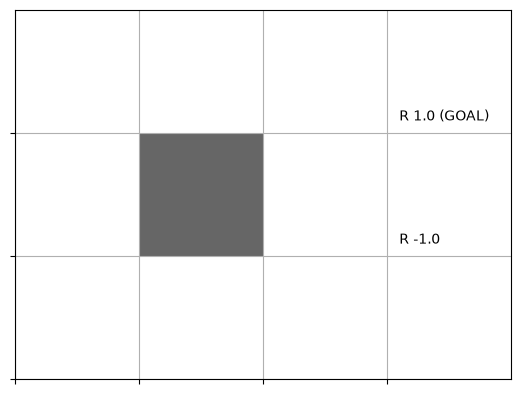

In [2]:
import numpy as np
env = GridWorld()
env.render_v()

### 3x4 그리드 월드시각화(더미 상태 가치 함수 입력)

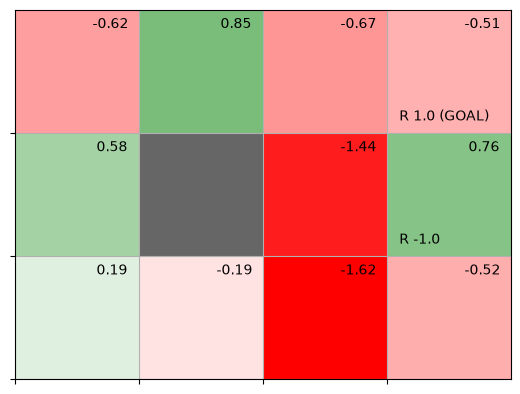

In [3]:
env = GridWorld()
V = {}

for state in env.states():
    V[state] = np.random.randn() # 더미 상태 가치 함수 
env.render_v(V)

### 상태-행동 쌍에 대해 상태 전이와 보상을 확인

환경은 결정적 전이 모델이므로, 어떤 상태 s에서 행동 a를 취하면 다음 상태 s'는 항상 하나로 정해집니다. 아래 예시는 `env.next_state(state, action)`과 `env.reward(state, action, next_state)`가 어떻게 계산되는지 보여줍니다.

- `(0, 0)`, 위쪽: 경계 밖으로 이동하려 하므로 제자리에 머뭅니다. 보상은 0입니다.
- `(1, 0)`, 오른쪽: 벽 `(1, 1)` 쪽으로 이동하려 하므로 제자리입니다. 보상은 0입니다.
- `(0, 2)`, 오른쪽: 목표 칸 `(0, 3)`으로 이동하므로 즉시 +1의 보상을 받고 종료됩니다.
- `(0, 3)`, 왼쪽: 이미 목표 상태이므로 추가 보상 없이 0을 받습니다. 종료 상태는 계속 유지됩니다.
- `(0, 2)`, 아래쪽: 일반 칸 `(1, 2)`로 이동하므로 보상은 0입니다.
- `(2, 3)`, 위쪽: 폭탄 칸 `(1, 3)`에 도착하므로 즉시 -1의 보상을 받습니다. 폭탄은 종료가 아니라 계속 진행할 수 있습니다.
- `(1, 3)`, 오른쪽: 폭탄 칸에서 경계 밖으로 나가려 하므로 제자리이며, 폭탄 보상인 -1을 받습니다.


In [4]:

examples = [
    ((0, 0), 0),  # 위쪽 경계 → 제자리
    ((1, 0), 3),  # 벽 → 제자리
    ((0, 2), 3),  # 목표 → +1, 종료
    ((0, 3), 2),  # 종료 이후 → 제자리, 추가 보상 0
    ((0, 2), 1),  # 일반 칸으로 이동
    ((2, 3), 0),  # 폭탄 → -1, 계속 진행
    ((1, 3), 3),  # 폭탄에서 오른쪽 경계 → 제자리, -1
]
# 각 예시 상태-행동 쌍에 대해 상태 전이와 보상을 확인
for state, action in examples:
    next_state = env.next_state(state, action)
    reward = env.reward(state, action, next_state)
    print(
        f"{state} / {env.action_meaning[action]:5s} → {next_state}, "
        f"보상={reward:+.0f}, 종료={next_state == env.goal_state}"
    )


(0, 0) / UP    → (0, 0), 보상=+0, 종료=False
(1, 0) / RIGHT → (1, 0), 보상=+0, 종료=False
(0, 2) / RIGHT → (0, 3), 보상=+1, 종료=True
(0, 3) / LEFT  → (0, 3), 보상=+0, 종료=True
(0, 2) / DOWN  → (1, 2), 보상=+0, 종료=False
(2, 3) / UP    → (1, 3), 보상=-1, 종료=False
(1, 3) / RIGHT → (1, 3), 보상=-1, 종료=False


### 반복적 정책 평가 

In [5]:
from collections import defaultdict

# 상태-행동 쌍을 기반으로 한 번의 벨만 기대값 갱신을 수행하는 함수
# pi: 정책 (상태별 행동 확률)
# V: 현재 가치 함수
# env: GridWorld 환경
# gamma: 할인율
def eval_onestep(pi, V, env, gamma=0.9):
    # 모든 상태를 순회하면서 각 상태의 새로운 가치를 계산
    for state in env.states():
        # 목표 상태는 종료 상태이므로 가치가 0
        if state == env.goal_state:
            V[state] = 0
            continue

        # 현재 상태에서 가능한 행동과 그 행동을 선택할 확률
        action_probs = pi[state]
        new_V = 0

        # 각 행동에 대해 기대값을 계산
        for action, action_prob in action_probs.items():
            # 행동을 취했을 때의 다음 상태와 즉시 보상
            next_state = env.next_state(state, action)
            r = env.reward(state, action, next_state)

            # 상태 s에서 행동 a를 수행할 때의 기대 가치
            # = 즉시 보상 + 할인된 미래 가치
            new_V += action_prob * (r + gamma * V[next_state])

        # 갱신된 상태 가치를 저장
        V[state] = new_V
    return V


# 정책 평가: 가치 함수가 수렴할 때까지 반복적으로 업데이트
# threshold: 수렴 기준. 최대 변화량이 이 값보다 작아지면 종료
def policy_eval(pi, V, env, gamma, threshold=0.001):
    while True:
        # 이전 가치 함수를 저장해 비교용으로 사용
        old_V = V.copy()

        # 한 번의 벨만 기대 갱신 수행
        V = eval_onestep(pi, V, env, gamma)

        # 최대 가치 변화량(delta)을 계산
        delta = 0
        for state in V.keys():
            t = abs(V[state] - old_V[state])
            if delta < t:
                delta = t

        # 변화량이 너무 작아지면 수렴했다고 판단하고 종료
        if delta < threshold:
            break

    return V



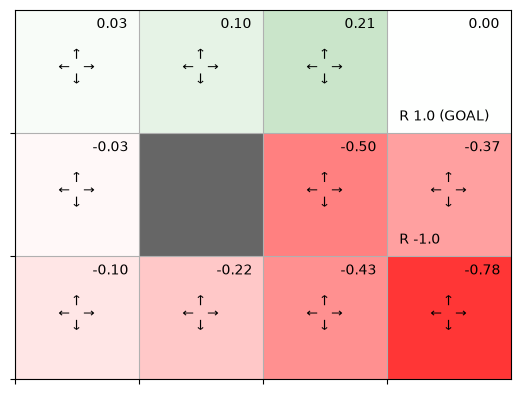

In [6]:
# 환경 객체와 할인율 설정
env = GridWorld()
gamma = 0.9

# 균등 랜덤 정책:
# 각 상태에서 네 가지 행동을 동일한 확률(0.25)로 선택
pi = {}
for state in env.states():
    pi[state] = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}

# 가치 함수 초기화: 모든 상태의 가치 0으로 시작
V = {}
for state in env.states():
    V[state] = 0.0

# 정책 평가를 수행해서 가치 함수를 계산
V = policy_eval(pi, V, env, gamma)

# 계산된 가치 함수를 시각화
env.render_v(V, pi)

## 2. 정책반복법 (Policy Iteration)

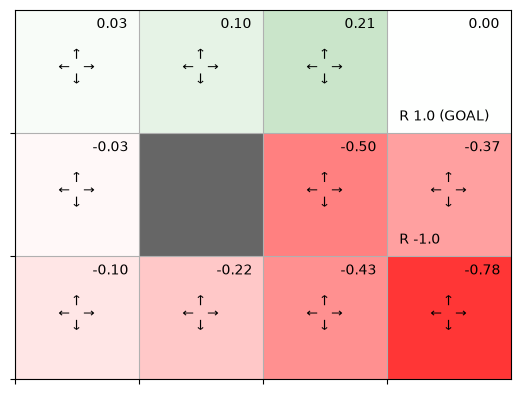

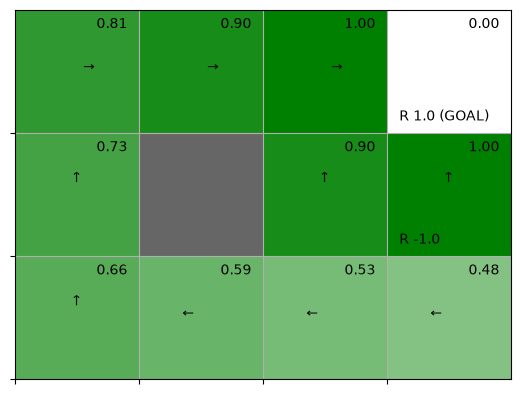

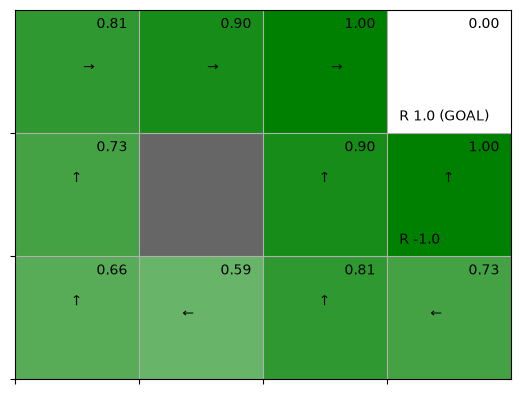

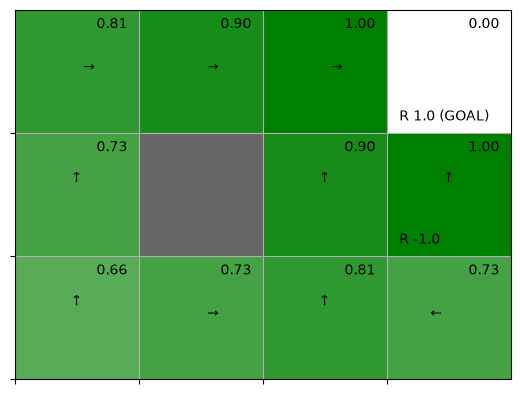

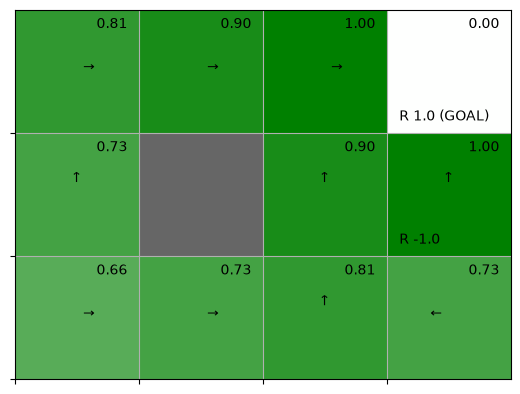

In [10]:
def argmax(d):
    """딕셔너리에서 최댓값을 가진 키를 반환한다."""
    max_value = max(d.values())
    max_key = -1

    # 최댓값을 가진 키를 찾는다.
    for key, value in d.items():
        if value == max_value:
            max_key = key

    return max_key


def greedy_policy(V, env, gamma):
    """가치 함수 V를 기준으로 탐욕적 정책을 생성한다."""
    pi = {}

    # 각 상태에서 가치가 가장 높은 행동을 선택한다.
    for state in env.states():
        action_values = {}

        # 각 행동의 즉시 보상과 할인된 미래 가치를 계산한다.
        for action in env.actions():
            next_state = env.next_state(state, action)
            r = env.reward(state, action, next_state)
            action_values[action] = r + gamma * V[next_state]

        max_action = argmax(action_values)

        # 선택한 행동의 확률을 1로 설정한다.
        action_probs = {0: 0, 1: 0, 2: 0, 3: 0}
        action_probs[max_action] = 1.0
        pi[state] = action_probs

    return pi


def policy_iter(env, gamma, threshold=0.001, is_render=True):
    """정책 반복법으로 최적 정책을 찾는다."""
    # 모든 행동을 같은 확률로 선택하는 초기 정책을 설정한다.
    pi = {}
    for state in env.states():
        pi[state] = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}

    # 모든 상태의 가치를 0으로 초기화한다.
    V = {}
    for state in env.states():
        V[state] = 0.0

    while True:
        # 현재 정책을 평가한다.
        V = policy_eval(pi, V, env, gamma, threshold)

        # 평가한 가치 함수를 바탕으로 정책을 개선한다.
        new_pi = greedy_policy(V, env, gamma)

        if is_render:
            env.render_v(V, pi)

        # 정책이 바뀌지 않으면 반복을 종료한다.
        if new_pi == pi:
            break

        pi = new_pi

    return pi


# 환경과 할인율을 설정한다.
env = GridWorld()
gamma = 0.9

# 정책 반복법으로 정책을 계산한다.
pi = policy_iter(env, gamma)

## 3. 가치 반복법 (Value Iteration)

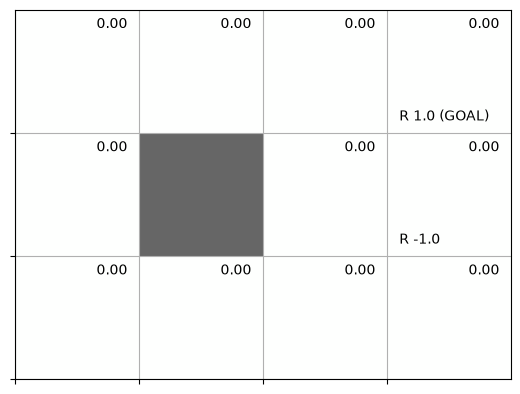

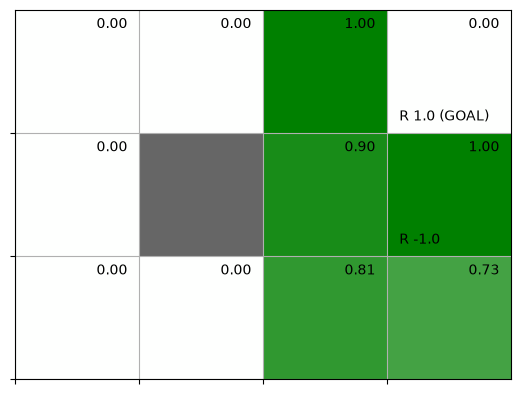

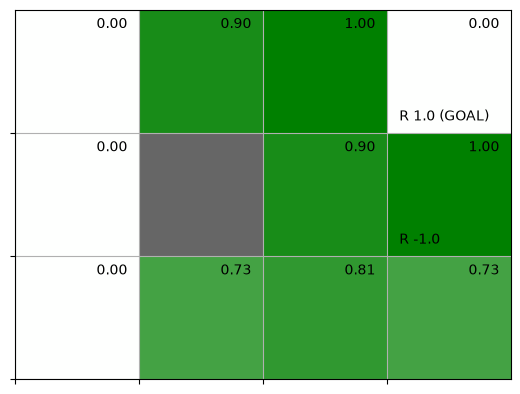

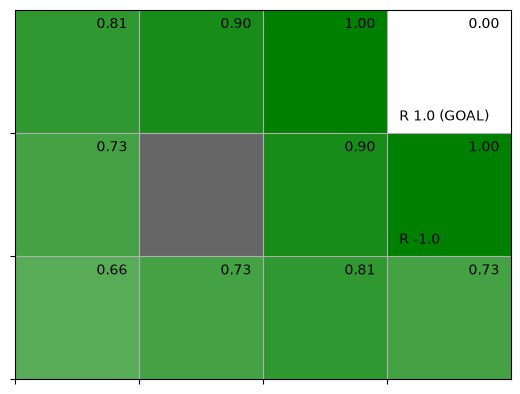

In [11]:



def value_iter_onestep(V, env, gamma):
    """모든 상태의 가치를 한 번 갱신한다."""
    for state in env.states():
        # 목표 상태의 가치는 0으로 설정한다.
        if state == env.goal_state:
            V[state] = 0
            continue

        action_values = []
        for action in env.actions():
            # 행동에 따른 즉시 보상과 할인된 미래 가치를 계산한다.
            next_state = env.next_state(state, action)
            r = env.reward(state, action, next_state)
            action_values.append(r + gamma * V[next_state])

        # 가능한 행동 중 가장 높은 가치를 상태 가치로 설정한다.
        V[state] = max(action_values)

    return V


def value_iter(V, env, gamma, threshold=0.001, is_render=True):
    """가치 반복법으로 가치 함수를 계산한다."""
    while True:
        if is_render:
            env.render_v(V)

        # 갱신 전 가치 함수를 저장한다.
        old_V = V.copy()
        V = value_iter_onestep(V, env, gamma)

        # 갱신 전후 가치 함수의 최대 차이를 계산한다.
        delta = 0
        for state in V.keys():
            change = abs(V[state] - old_V[state])
            delta = max(delta, change)

        # 최대 변화량이 임계값보다 작으면 반복을 종료한다.
        if delta < threshold:
            break

    return V


# 가치 함수를 0으로 초기화한다.
V = defaultdict(lambda: 0)
env = GridWorld()
gamma = 0.9

# 가치 반복법으로 최적 가치 함수를 계산한다.
V = value_iter(V, env, gamma)


### 탐욕적 정책으로 최적 행동 선택

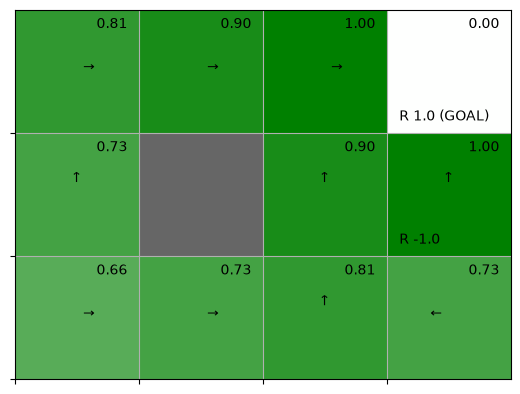

In [9]:
pi = greedy_policy(V, env, gamma)
env.render_v(V, pi)